# Simple Linear Regression

Companion notebook to the note [Simple Linear Regression](../../notes/regression/simple_linear_regression.md) and the [exercises](../../exercises/regression/simple_linear_regression.md).

We fit $y_i=\beta_0+\beta_1x_i+\varepsilon_i$ by least squares, check the sum-of-squares identity $\mathrm{SST}=\mathrm{SSR}+\mathrm{SSE}$, do inference on the slope, and look at residual diagnostics, sampling variability, and leverage.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

rng = np.random.default_rng(42)
plt.rcParams['figure.figsize'] = (7, 4.5)

## 1. Least squares by hand

The slope is $\hat\beta_1=S_{xy}/S_{xx}$ and the intercept is $\hat\beta_0=\bar y-\hat\beta_1\bar x$. We apply this to a small noisy data set (the one used in the exercises) and compare with `numpy.polyfit`.

In [2]:
x = np.array([1, 2, 3, 4, 5], dtype=float)
y = np.array([2, 4, 5, 4, 5], dtype=float)

Sxx = np.sum((x - x.mean())**2)
Sxy = np.sum((x - x.mean()) * (y - y.mean()))
b1 = Sxy / Sxx
b0 = y.mean() - b1 * x.mean()
print(f"Sxx={Sxx:.1f}, Sxy={Sxy:.1f}, slope={b1:.3f}, intercept={b0:.3f}")
print("polyfit check:", np.polyfit(x, y, 1))

Sxx=10.0, Sxy=6.0, slope=0.600, intercept=2.200
polyfit check: [0.6 2.2]


## 2. Sums of squares and $R^2$

$\mathrm{SST}=\sum(y_i-\bar y)^2$, $\mathrm{SSE}=\sum(y_i-\hat y_i)^2$, $\mathrm{SSR}=\sum(\hat y_i-\bar y)^2$. With an intercept, $\mathrm{SST}=\mathrm{SSR}+\mathrm{SSE}$, residuals sum to zero and are orthogonal to $x$. In simple regression $R^2=r_{xy}^2$.

In [3]:
y_hat = b0 + b1 * x
e = y - y_hat
SST = np.sum((y - y.mean())**2)
SSE = np.sum(e**2)
SSR = np.sum((y_hat - y.mean())**2)
print(f"SST={SST:.2f}  SSR={SSR:.2f}  SSE={SSE:.2f}  SSR+SSE={SSR+SSE:.2f}")
print(f"R^2 = {SSR/SST:.3f},  r^2 = {np.corrcoef(x, y)[0,1]**2:.3f}")
print(f"sum(e) = {e.sum():.1e},  sum(x*e) = {(x*e).sum():.1e}")

SST=6.00  SSR=3.60  SSE=2.40  SSR+SSE=6.00
R^2 = 0.600,  r^2 = 0.600
sum(e) = -4.4e-16,  sum(x*e) = -4.4e-16


## 3. Inference on the slope

With $s^2=\mathrm{SSE}/(n-2)$, $\mathrm{SE}(\hat\beta_1)=s/\sqrt{S_{xx}}$ and $t=\hat\beta_1/\mathrm{SE}(\hat\beta_1)\sim t_{n-2}$ under $H_0:\beta_1=0$. We compute these by hand and compare with `statsmodels`. With $n=5$ the test has only 3 degrees of freedom, so the interval is wide.

In [4]:
n = len(x)
s = np.sqrt(SSE / (n - 2))
se_b1 = s / np.sqrt(Sxx)
t_stat = b1 / se_b1
p_val = 2 * stats.t.sf(abs(t_stat), n - 2)
tcrit = stats.t.ppf(0.975, n - 2)
print(f"s={s:.3f}, SE(b1)={se_b1:.3f}, t={t_stat:.3f}, p={p_val:.3f}")
print(f"95% CI for slope: ({b1 - tcrit*se_b1:.3f}, {b1 + tcrit*se_b1:.3f})")

fit = sm.OLS(y, sm.add_constant(x)).fit()
print(fit.summary().tables[1])

s=0.894, SE(b1)=0.283, t=2.121, p=0.124
95% CI for slope: (-0.300, 1.500)
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.2000      0.938      2.345      0.101      -0.785       5.185
x1             0.6000      0.283      2.121      0.124      -0.300       1.500


/tmp/claude-1000/-home-adam-my-repos-Statistics-Notes/348b9543-6167-4bef-ba53-2f12bf33edb1/scratchpad/venv/lib/python3.12/site-packages/statsmodels/regression/linear_model.py:3158: ValueWarning: omni_normtest is not valid with less than 8 observations; 5 samples were given.
  omni, omnipv = cached("omni_normtest", lambda: omni_normtest(self.wresid))


## 4. Fitted line with confidence and prediction bands

On a larger simulated sample (true $\beta_0=2,\ \beta_1=0.5,\ \sigma=1.5$), the confidence band for the mean response is narrower than the prediction band for a new observation, and both are narrowest at $\bar x$.

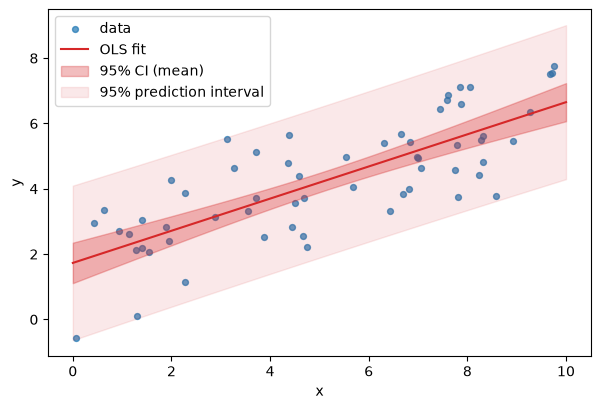

[1.72999118 0.49218474] 0.6036373178510892


In [5]:
n = 60
xs = rng.uniform(0, 10, n)
ys = 2 + 0.5 * xs + rng.normal(0, 1.5, n)
res = sm.OLS(ys, sm.add_constant(xs)).fit()
grid = np.linspace(0, 10, 100)
pred = res.get_prediction(sm.add_constant(grid)).summary_frame(alpha=0.05)

fig, ax = plt.subplots()
ax.scatter(xs, ys, s=18, alpha=0.7, label='data')
ax.plot(grid, pred['mean'], color='C3', label='OLS fit')
ax.fill_between(grid, pred['mean_ci_lower'], pred['mean_ci_upper'], color='C3', alpha=0.3, label='95% CI (mean)')
ax.fill_between(grid, pred['obs_ci_lower'], pred['obs_ci_upper'], color='C3', alpha=0.1, label='95% prediction interval')
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.legend()
plt.show()
print(res.params, res.rsquared)

## 5. Residual diagnostics

Residuals vs fitted values should show no pattern (linearity, equal variance) and the Q-Q plot should be close to a straight line (normality). Here the data are generated from the model, so both look healthy.

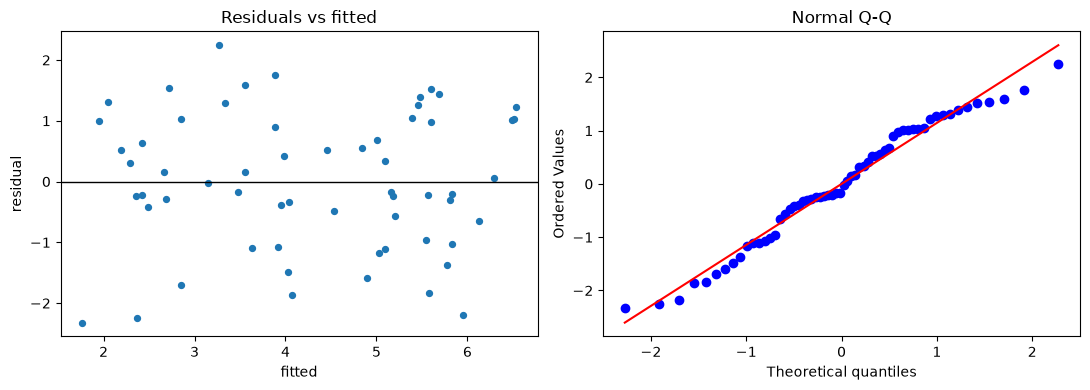

Shapiro-Wilk p-value: 0.186


In [6]:
resid = res.resid
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(res.fittedvalues, resid, s=18)
axes[0].axhline(0, color='k', lw=1)
axes[0].set_xlabel('fitted'); axes[0].set_ylabel('residual'); axes[0].set_title('Residuals vs fitted')
stats.probplot(resid, dist='norm', plot=axes[1])
axes[1].set_title('Normal Q-Q')
plt.tight_layout(); plt.show()
print("Shapiro-Wilk p-value:", round(stats.shapiro(resid).pvalue, 3))

## 6. Sampling distribution of the slope

Repeating the experiment 2000 times shows that $\hat\beta_1$ is centred at the true value (unbiased), that its spread matches $\sigma/\sqrt{S_{xx}}$, and that nominal 95% intervals cover the truth about 95% of the time.

mean slope = 0.499, sd = 0.089, theory sd = 0.092
CI coverage = 0.953


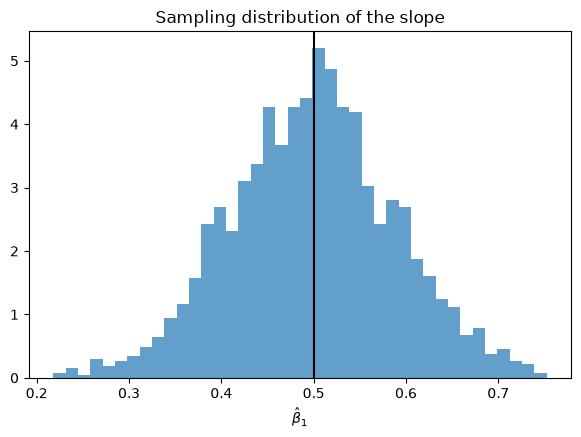

In [7]:
beta0, beta1, sigma, n = 2.0, 0.5, 1.5, 30
x_fixed = np.linspace(0, 10, n)
Sxx_f = np.sum((x_fixed - x_fixed.mean())**2)
slopes, covered = [], 0
tc = stats.t.ppf(0.975, n - 2)
for _ in range(2000):
    yy = beta0 + beta1 * x_fixed + rng.normal(0, sigma, n)
    b1_ = np.sum((x_fixed - x_fixed.mean()) * (yy - yy.mean())) / Sxx_f
    b0_ = yy.mean() - b1_ * x_fixed.mean()
    s_ = np.sqrt(np.sum((yy - b0_ - b1_ * x_fixed)**2) / (n - 2))
    half = tc * s_ / np.sqrt(Sxx_f)
    covered += (b1_ - half <= beta1 <= b1_ + half)
    slopes.append(b1_)
slopes = np.array(slopes)
print(f"mean slope = {slopes.mean():.3f}, sd = {slopes.std(ddof=1):.3f}, theory sd = {sigma/np.sqrt(Sxx_f):.3f}")
print(f"CI coverage = {covered/2000:.3f}")
plt.hist(slopes, bins=40, density=True, alpha=0.7)
plt.axvline(beta1, color='k'); plt.xlabel(r'$\hat\beta_1$'); plt.title('Sampling distribution of the slope')
plt.show()

## 7. Leverage and influence

A point far from $\bar x$ has high leverage $h_{ii}=1/n+(x_i-\bar x)^2/S_{xx}$. Adding the single point $(10,5)$ to the small data set changes the slope from 0.6 to about 0.23.

slope before/after: 0.6 0.233
R^2 before/after: 0.6 0.403
leverages: [0.364 0.259 0.193 0.167 0.18  0.836]


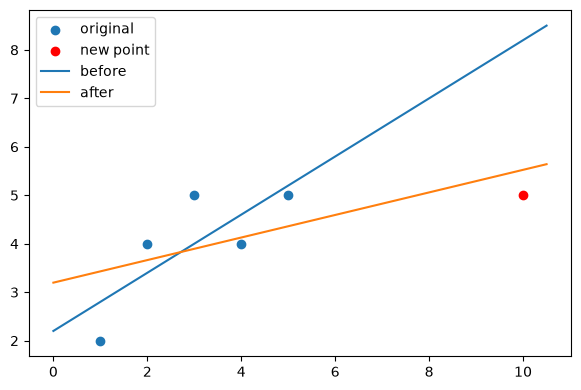

In [8]:
x2 = np.append(x, 10.0); y2 = np.append(y, 5.0)
fit2 = sm.OLS(y2, sm.add_constant(x2)).fit()
h = fit2.get_influence().hat_matrix_diag
print("slope before/after:", round(b1, 3), round(fit2.params[1], 3))
print("R^2 before/after:", round(fit.rsquared, 3), round(fit2.rsquared, 3))
print("leverages:", np.round(h, 3))
plt.scatter(x, y, label='original'); plt.scatter(10, 5, color='r', label='new point')
g = np.linspace(0, 10.5, 50)
plt.plot(g, b0 + b1 * g, label='before'); plt.plot(g, fit2.params[0] + fit2.params[1] * g, label='after')
plt.legend(); plt.show()